In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Fault Labels

In [3]:
canopy_2015 = pd.read_csv("/content/drive/MyDrive/NIST_Preprocessed/canopy_2015_Labeled.csv")
canopy_2016 = pd.read_csv("/content/drive/MyDrive/NIST_Preprocessed/canopy_2016_Labeled.csv")

In [4]:
# Fault Indicator Columns
# Rather than merging label_string/label_inverter into a single priority-ordered
# column (which would hide genuine co-occurrence between fault types), we keep
# both label sets fully separate and add lightweight boolean indicators on top.
# This supports both a coarse "fault vs no-fault" detection task and full
# subsystem-level classification, without discarding information.

NON_FAULT_VALUES = ['NORMAL', 'NOT_EVALUABLE', 'MISSING_DATA', 'INSUFFICIENT_DATA']

canopy_2015['has_string_fault']   = ~canopy_2015['label_string'].isin(NON_FAULT_VALUES)
canopy_2015['has_inverter_fault'] = ~canopy_2015['label_inverter'].isin(NON_FAULT_VALUES)
canopy_2015['has_any_fault']      = canopy_2015['has_string_fault'] | canopy_2015['has_inverter_fault']
canopy_2015['fault_cooccurrence'] = canopy_2015['has_string_fault'] & canopy_2015['has_inverter_fault']

# Summary
print("=== Fault Indicator Summary (2015) ===\n")
print(f"has_string_fault   : {canopy_2015['has_string_fault'].sum()}")
print(f"has_inverter_fault : {canopy_2015['has_inverter_fault'].sum()}")
print(f"has_any_fault      : {canopy_2015['has_any_fault'].sum()}")
print(f"fault_cooccurrence : {canopy_2015['fault_cooccurrence'].sum()}")

print(f"\nAs % of evaluable rows (Op_Mask=1): "
      f"{canopy_2015.loc[canopy_2015['Op_Mask']==1, 'has_any_fault'].mean() * 100:.2f}%")

=== Fault Indicator Summary (2015) ===

has_string_fault   : 11146
has_inverter_fault : 10380
has_any_fault      : 20801
fault_cooccurrence : 725

As % of evaluable rows (Op_Mask=1): 10.92%


In [5]:
NON_FAULT_VALUES = ['NORMAL', 'NOT_EVALUABLE', 'MISSING_DATA', 'INSUFFICIENT_DATA']

canopy_2016['has_string_fault']   = ~canopy_2016['label_string'].isin(NON_FAULT_VALUES)
canopy_2016['has_inverter_fault'] = ~canopy_2016['label_inverter'].isin(NON_FAULT_VALUES)
canopy_2016['has_any_fault']      = canopy_2016['has_string_fault'] | canopy_2016['has_inverter_fault']
canopy_2016['fault_cooccurrence'] = canopy_2016['has_string_fault'] & canopy_2016['has_inverter_fault']

# Summary
print("=== Fault Indicator Summary (2016) ===\n")
print(f"has_string_fault   : {canopy_2016['has_string_fault'].sum()}")
print(f"has_inverter_fault : {canopy_2016['has_inverter_fault'].sum()}")
print(f"has_any_fault      : {canopy_2016['has_any_fault'].sum()}")
print(f"fault_cooccurrence : {canopy_2016['fault_cooccurrence'].sum()}")

print(f"\nAs % of evaluable rows (Op_Mask=1): "
      f"{canopy_2016.loc[canopy_2016['Op_Mask']==1, 'has_any_fault'].mean() * 100:.2f}%")

=== Fault Indicator Summary (2016) ===

has_string_fault   : 7610
has_inverter_fault : 11428
has_any_fault      : 18442
fault_cooccurrence : 596

As % of evaluable rows (Op_Mask=1): 9.54%


#Stage 1: CS-LSTM Regression Description

In [ ]:
"""
References Paper: "A Comprehensive Framework for Predictive Maintenance in Solar
          Photovoltaic Systems Using Contextual Deep Model"

Objective:
  Predict the expected AC power output (InvPAC_kW_Avg) under normal
  operating conditions by leveraging both operational data and contextual features
  (season and time of day) through Kronecker product expansion

  The residual (measured - expected) that is produced here is used as
  anomaly signal in Stage 2 (XGBoost classifier).

Mathematics:
  Standard LSTM:  gate = σ(W_h·h_{t-1}  +  W_x·x_t           + b)
  CS-LSTM:        gate = σ(W_h·h_{t-1}  +  B·(x_t ⊗ Γ(z_t))  + b)

  where:
    x_t   = primary features (operational data) at timestep t
    z_t   = contextual features (season, time-of-day encodings)
    Γ(z_t) = polynomial basis functions of z_t (degree 2)
    ⊗     = Kronecker product → expanded input vector

  This means that the gate weights of LSTM become functions of
  context - meaning. the model learns that "On July at 12:00 the
  irradiance has a different importance than that of December".
"""

# Hyperparameters (από Baruah et al. 2025 + adaptation)

Info = {
    "train_years":       [2015, 2016],
    "val_year":          2017,
    "test_year":         2018,
    "irr_threshold":     100.0,        # W/m² - operating mask

    # Features
    "primary_features": [              # Inverter signals = x_t
        "POA_fused",                   # POA irradiance
        "AmbTemp_C_Avg",               # ambient temperature
        "module_temp",                 # module temperature
        "InvVDCin_Avg",                # DC voltage
        "InvIDCin_Avg",                # DC current
        "InvPDC_kW_Avg",               # DC power
        "InvPAC_kW_Avg_lag1",          # previous AC power
    ],
    "target":            "InvPAC_kW_Avg",
    "poly_degree":       [2,3],            # polynomial basis degree for Γ(z_t)

    # Model
    "seq_len":           [5,10,15,30,60],           # timesteps per window
    "hidden_size":       [10, 15, 20, 25, 30],       # LSTM hidden units (από Baruah et al.)
    "num_layers":        [1,2],            # LSTM layers (από Baruah et al.)
    "dropout":           [0.1, 0.2, 0.3],

    # Training
    "batch_size":        [64, 128, 256],
    "lr":                [1e-5, 1e-3],       # learning rate (από Baruah et al.)
    "epochs":            [50-150],
    "weight_decay":      1e-6,
}

# Parameters (NIST Canopy)
P_AC_RATED_KW = 260.0   # Inverter rated AC power (kW) PVP260kW
P_DC_NOM_KW   = 243.0   # DC Nameplate power (kW)

In [ ]:
"""
Stage 4:
    Υπολογισμός του Γ(z_t) — polynomial basis functions of z_t.

    Input:
      z      : Τα contextual features (sin_doy, cos_doy, sin_hour, cos_hour)
      degree : polynomial degree 2

    Output:
      basis  :  Πολυωνυμικά γινόμενα μέχρι βαθμού 2

    Παράδειγμα για degree=2, z=[z1, z2]:
      Γ(z) = [1, z1, z2, z1², z1*z2, z2²]

    """

"""Stage 5:

    Υπολογισμός του Kronecker product x_t ⊗ Γ(z_t).

    Input:
      x_t
      Γ(z_t)

    Μαθηματικά:
      [x1, x2] ⊗ [γ1, γ2, γ3] = [x1*γ1, x1*γ2, x1*γ3, x2*γ1, x2*γ2, x2*γ3]

    Αυτό επιτρέπει στο LSTM να έχει ξεχωριστά βαρη για κάθε combination δηλαδή
    η ακτινοβολία έχει διαφορετικό weight ανάλογα με την εποχή και ώρα.
    """

"""
    Stage 5:
    Context-Sensitive LSTM Regression Model

    Αρχιτεκτονική:
      1. Input: x_expanded = x_t ⊗ Γ(z_t)
      2. LSTM layers: εκμάθηση temporal dependencies
      3. FC output layer: πρόβλεψη InvPAC_kW_Avg

    Το μοντέλο εκπαιδεύεται μόνο σε confirmed-normal data.
    Κατά inference, τρέχει σε ολα τα data (normal + faulty)
    για να παράξει residuals.
    """

"""
    Stage 6: Evaluation

    Χρησιμοποιούμε μετρικές όπως RMSE, NRMSE για να κάνουμε την ελαχιστοποιήση των residuals μεταξύ προβλεπόμενης InvPAC_kw_Avg και predicted InvPAC_kW_Avg
    """

#Pipeline

In [9]:
# Cell: Configuration

PRIMARY_FEATURES = [
    'POA_fused',
    'AmbTemp_C_Avg',
    'module_temp',
    'InvVDCin_Avg',
    'InvIDCin_Avg',
    'InvPDC_kW_Avg',
    'I_string_mean',
    'InvPAC_kW_Avg_lag1',
]

CONTEXTUAL_FEATURES = [
    'sin_doy',
    'cos_doy',
    'sin_hour',
    'cos_hour',
]

TARGET  = 'InvPAC_kW_Avg'
SEQ_LEN = 45   # 60-minute look-back window

In [10]:
#  Cell: Feature Engineering

def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Προσθέτει:
      1. Lag feature: InvPAC_kW_Avg_lag1 (autoregressive)
      2. Contextual encodings: sin/cos για εποχή και ώρα

    """
    df = df.copy()

    # Lag
    df['InvPAC_kW_Avg_lag1'] = df['InvPAC_kW_Avg'].shift(1)

    # DatetimeIndex
    if 'TIMESTAMP' in df.columns:
        df.index = pd.to_datetime(df['TIMESTAMP'])

    doy  = df.index.day_of_year.values
    hour = df.index.hour.values + df.index.minute.values / 60.0

    df['sin_doy']  = np.sin(2 * np.pi * doy  / 365.0)
    df['cos_doy']  = np.cos(2 * np.pi * doy  / 365.0)
    df['sin_hour'] = np.sin(2 * np.pi * hour / 24.0)
    df['cos_hour'] = np.cos(2 * np.pi * hour / 24.0)

    return df

In [11]:
#  Cell: Build Operating Dataset (Βήμα 1 & 2)
#
# ΣΩΣΤΗ ΣΕΙΡΑ:
#   Βήμα 1 → Op_Mask=1 μόνο (νύχτα/χαμηλή ακτινοβολία = φυσικό gap)
#   Βήμα 2 → add_features
#   Βήμα 3 → continuity groups στο ΠΛΗΡΕΣ operating dataset
#   Βήμα 4 → fault exclusion γίνεται ΕΝΤΟΣ του windowing (αργότερα)
#
# ΔΕΝ αφαιρούμε faults εδώ — αν αφαιρέσουμε, τα fault timestamps
# δημιουργούν ψεύτικα gaps που σπάνε τη συνέχεια σε χιλιάδες micro-groups.

df_2015 = canopy_2015[canopy_2015['Op_Mask'] == 1].copy()
df_2016 = canopy_2016[canopy_2016['Op_Mask'] == 1].copy()

df_operating = pd.concat([df_2015, df_2016])
df_operating = add_features(df_operating)
df_operating = df_operating.dropna(
    subset=PRIMARY_FEATURES + CONTEXTUAL_FEATURES + [TARGET]
)
df_operating = df_operating.sort_index()

print(f"Operating rows (Op_Mask=1): {len(df_operating):,}")
print(f"  2015: {len(df_2015):,}")
print(f"  2016: {len(df_2016):,}")
print(f"\nFault breakdown within operating rows:")
print(f"  has_any_fault == True:  "
      f"{df_operating['has_any_fault'].sum():,}  "
      f"({100*df_operating['has_any_fault'].mean():.2f}%)")
print(f"  has_any_fault == False: "
      f"{(~df_operating['has_any_fault']).sum():,}  "
      f"({100*(~df_operating['has_any_fault']).mean():.2f}%)")

Operating rows (Op_Mask=1): 383,724
  2015: 190,478
  2016: 193,285

Fault breakdown within operating rows:
  has_any_fault == True:  39,229  (10.22%)
  has_any_fault == False: 344,495  (89.78%)


In [12]:
#  Cell: Continuity Groups (Βήμα 3)

def assign_continuity_groups(df: pd.DataFrame,
                              max_gap_minutes: int = 1) -> pd.DataFrame:
    """
    Αναθέτει group ID σε κάθε row.
    Νέο group ξεκινά όταν η χρονική διαφορά > 1 λεπτό.

    Τα gaps εδώ αντικατοπτρίζουν ΜΟΝΟ φυσικά breaks
    (νύχτα → πρωί) επειδή δεν έχουμε αφαιρέσει fault rows.
    """
    df = df.copy()
    time_diff = df.index.to_series().diff()
    gap_mask  = time_diff > pd.Timedelta(minutes=max_gap_minutes)
    df['continuity_group'] = gap_mask.cumsum().astype(int)

    sizes = df.groupby('continuity_group').size()
    usable = (sizes >= SEQ_LEN).sum()

    print(f"Continuity groups:          {len(sizes):>8,}")
    print(f"  min size (timesteps):     {sizes.min():>8,}")
    print(f"  median size (timesteps):  {sizes.median():>8,.0f}")
    print(f"  max size (timesteps):     {sizes.max():>8,}")
    print(f"  Groups ≥ SEQ_LEN ({SEQ_LEN}): {usable:>8,}  ← usable for windowing")

    return df

df_operating = assign_continuity_groups(df_operating)

Continuity groups:             2,677
  min size (timesteps):            1
  median size (timesteps):        13
  max size (timesteps):          797
  Groups ≥ SEQ_LEN (45):      910  ← usable for windowing


In [10]:
# Dataset & DataLoader

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

class CSLSTMDataset(Dataset):
    """
    Sliding window dataset για CS-LSTM.

    Λογική:
      - Ξεκινά από το πλήρες operating dataset (Op_Mask=1)
      - Continuity groups ήδη ανατεθειμένα
      - Εντός κάθε group → sliding windows με step=1
      - Κρατά μόνο windows όπου ΟΛΑ τα timesteps είναι normal
        (has_any_fault==False AND InvOpStatus_Avg>0)
    """

    def __init__(self,
                 df,
                 primary_cols,
                 context_cols,
                 target_col,
                 seq_len,
                 scaler_x=None,
                 scaler_y=None,
                 fit_scaler=False):

        self.seq_len = seq_len

        # Normal mask — True όπου το timestep είναι fully clean
        normal_mask = (
            (df['has_any_fault'] == False) &
            (df['InvOpStatus_Avg'] > 0)
        ).values

        X_raw  = df[primary_cols].values.astype(np.float32)
        Z_raw  = df[context_cols].values.astype(np.float32)
        Y_raw  = df[target_col].values.astype(np.float32)
        groups = df['continuity_group'].values

        # Scalers
        # Fit ΜΟΝΟ στα normal rows του training set
        if fit_scaler:
            normal_idx    = np.where(normal_mask)[0]
            self.scaler_x = StandardScaler()
            self.scaler_y = StandardScaler()
            self.scaler_x.fit(X_raw[normal_idx])
            self.scaler_y.fit(Y_raw[normal_idx].reshape(-1, 1))
        else:
            self.scaler_x = scaler_x
            self.scaler_y = scaler_y

        X_scaled = self.scaler_x.transform(X_raw)
        Y_scaled = self.scaler_y.transform(
            Y_raw.reshape(-1, 1)
        ).flatten()

        #  Sliding windows εντός groups
        X_wins, Z_wins, Y_tgts = [], [], []
        skipped_small = 0
        skipped_fault = 0

        for g in np.unique(groups):
            idx = np.where(groups == g)[0]

            # Group πολύ μικρό για ένα window
            if len(idx) < seq_len:
                skipped_small += 1
                continue

            X_g = X_scaled[idx]
            Z_g = Z_raw[idx]
            Y_g = Y_scaled[idx]
            N_g = normal_mask[idx]

            for i in range(len(idx) - seq_len + 1):
                # Κρατάμε window μόνο αν ΟΛΑ τα timesteps είναι normal
                if not N_g[i : i + seq_len].all():
                    skipped_fault += 1
                    continue

                X_wins.append(X_g[i : i + seq_len])
                Z_wins.append(Z_g[i : i + seq_len])
                Y_tgts.append(Y_g[i + seq_len - 1])

        self.X = np.array(X_wins, dtype=np.float32)
        self.Z = np.array(Z_wins, dtype=np.float32)
        self.Y = np.array(Y_tgts, dtype=np.float32)

        print(f"  Windows accepted:         {len(self.X):>10,}")
        print(f"  Skipped (group too small):{skipped_small:>10,}")
        print(f"  Skipped (fault in window):{skipped_fault:>10,}")
        print(f"  X shape: {self.X.shape}")
        print(f"  Z shape: {self.Z.shape}")

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (
            torch.from_numpy(self.X[idx]),   # (seq_len, n_primary)
            torch.from_numpy(self.Z[idx]),   # (seq_len, n_context)
            torch.tensor(self.Y[idx])        # scalar
        )

In [11]:
#  Build Training Dataset

BATCH_SIZE = 128

print("=== Training Dataset (2015-2016) ===")
train_ds = CSLSTMDataset(
    df           = df_operating,
    primary_cols = PRIMARY_FEATURES,
    context_cols = CONTEXTUAL_FEATURES,
    target_col   = TARGET,
    seq_len      = SEQ_LEN,
    fit_scaler   = True
)

train_loader = DataLoader(
    train_ds,
    batch_size  = BATCH_SIZE,
    shuffle     = True,
    num_workers = 2,
    pin_memory  = True
)

print(f"\nBatch size:          {BATCH_SIZE}")
print(f"Train batches/epoch: {len(train_loader):,}")

=== Training Dataset (2015-2016) ===
  Windows accepted:            184,788
  Skipped (group too small):     1,840
  Skipped (fault in window):   130,167
  X shape: (184788, 60, 8)
  Z shape: (184788, 60, 4)

Batch size:          128
Train batches/epoch: 1,444


In [12]:
#  Validation Dataset (2017)

canopy_2017 = pd.read_csv(
    "/content/drive/MyDrive/NIST_Preprocessed/canopy_2017_Labeled.csv"
)

# Fault indicators (ίδια λογική με 2015/2016)
canopy_2017['has_string_fault']   = ~canopy_2017['label_string'].isin(NON_FAULT_VALUES)
canopy_2017['has_inverter_fault'] = ~canopy_2017['label_inverter'].isin(NON_FAULT_VALUES)
canopy_2017['has_any_fault']      = (canopy_2017['has_string_fault'] |
                                      canopy_2017['has_inverter_fault'])

# Operating rows μόνο, ΔΕΝ φιλτράρουμε faults πριν το grouping
df_val_operating = canopy_2017[canopy_2017['Op_Mask'] == 1].copy()
df_val_operating = add_features(df_val_operating)
df_val_operating = df_val_operating.dropna(
    subset=PRIMARY_FEATURES + CONTEXTUAL_FEATURES + [TARGET]
)
df_val_operating = df_val_operating.sort_index()
df_val_operating = assign_continuity_groups(df_val_operating)

print(f"\nOperating rows (2017): {len(df_val_operating):,}")
print(f"  has_any_fault: {df_val_operating['has_any_fault'].sum():,} "
      f"({100*df_val_operating['has_any_fault'].mean():.2f}%)")

print("\n=== Validation Dataset (2017) ===")
val_ds = CSLSTMDataset(
    df           = df_val_operating,
    primary_cols = PRIMARY_FEATURES,
    context_cols = CONTEXTUAL_FEATURES,
    target_col   = TARGET,
    seq_len      = SEQ_LEN,
    scaler_x     = train_ds.scaler_x,
    scaler_y     = train_ds.scaler_y,
    fit_scaler   = False        # ← ίδιοι scalers από training
)

val_loader = DataLoader(
    val_ds,
    batch_size  = BATCH_SIZE * 2,
    shuffle     = False,
    num_workers = 2,
    pin_memory  = True
)

print(f"\nVal batches/epoch: {len(val_loader):,}")

Continuity groups:             1,384
  min size (timesteps):            1
  median size (timesteps):        12
  max size (timesteps):          792
  Groups ≥ SEQ_LEN (60):      403  ← usable for windowing

Operating rows (2017): 191,955
  has_any_fault: 22,951 (11.96%)

=== Validation Dataset (2017) ===
  Windows accepted:             85,840
  Skipped (group too small):       981
  Skipped (fault in window):    71,451
  X shape: (85840, 60, 8)
  Z shape: (85840, 60, 4)

Val batches/epoch: 336


In [13]:
# CS-LSTM Model

import torch
import torch.nn as nn

class CSLSTM(nn.Module):
    """
    Υλοποίηση μέσω Kronecker product expansion:
      x_expanded = x_t ⊗ Γ(z_t)

    όπου Γ(z_t) = polynomial basis functions των contextual features.
    Αυτό κάνει τα gate weights functions του context χωρίς custom cell.

    Input per timestep:
      x_t : (n_primary,)   — scaled SCADA signals
      z_t : (n_context,)   — sin/cos contextual features

    Forward:
      1. Υπολογισμός Γ(z_t) για κάθε timestep
      2. Kronecker expansion: x_exp = x_t ⊗ Γ(z_t)
      3. LSTM πάνω στο x_exp
      4. FC layer → predicted InvPAC_kW_Avg
    """

    def __init__(self, n_primary, n_context, hidden_size,
                 num_layers, dropout, poly_degree):
        super().__init__()

        self.poly_degree = poly_degree

        # Υπολογισμός μεγέθους basis
        # Για degree=2, n_context=4: C(4+2,2) = 15
        l_basis    = self._basis_size(n_context, poly_degree)
        input_size = n_primary * l_basis

        print(f"CS-LSTM dimensions:")
        print(f"  n_primary:  {n_primary}")
        print(f"  n_context:  {n_context}")
        print(f"  l_basis:    {l_basis}  (degree-{poly_degree} polynomial)")
        print(f"  input_size: {input_size}  (= {n_primary} × {l_basis})")
        print(f"  hidden:     {hidden_size}")

        self.lstm = nn.LSTM(
            input_size  = input_size,
            hidden_size = hidden_size,
            num_layers  = num_layers,
            batch_first = True,
            dropout     = dropout if num_layers > 1 else 0.0
        )
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(hidden_size, 1)
        self._init_weights()

    def _basis_size(self, n, degree):
        """C(n + degree, degree) — αριθμός monomials."""
        from math import comb
        return comb(n + degree, degree)

    def _poly_basis(self, z):
        """
        Υπολογίζει Γ(z_t) — polynomial basis μέχρι degree d.

        Input:  z — (batch, seq, n_context)
        Output: γ — (batch, seq, l_basis)

        Για degree=2, z=[z1,z2,z3,z4]:
          γ = [1, z1, z2, z3, z4, z1², z1z2, z1z3, ..., z4²]
        """
        from itertools import combinations_with_replacement

        batch, seq, n = z.shape
        terms = [torch.ones(batch, seq, 1, device=z.device)]  # degree 0

        for d in range(1, self.poly_degree + 1):
            for combo in combinations_with_replacement(range(n), d):
                term = torch.ones(batch, seq, 1, device=z.device)
                for i in combo:
                    term = term * z[:, :, i:i+1]
                terms.append(term)

        return torch.cat(terms, dim=-1)   # (batch, seq, l_basis)

    def _init_weights(self):
        for name, p in self.lstm.named_parameters():
            if 'weight_ih' in name:
                nn.init.xavier_uniform_(p.data)
            elif 'weight_hh' in name:
                nn.init.orthogonal_(p.data)
            elif 'bias' in name:
                nn.init.zeros_(p.data)
        nn.init.xavier_uniform_(self.fc.weight)
        nn.init.zeros_(self.fc.bias)

    def forward(self, x, z):
        """
        x : (batch, seq_len, n_primary)
        z : (batch, seq_len, n_context)
        → y_pred : (batch,)
        """
        gamma   = self._poly_basis(z)           # (batch, seq, l_basis)

        # Kronecker product: x ⊗ γ
        # (batch, seq, n_primary, 1) × (batch, seq, 1, l_basis)
        # → (batch, seq, n_primary, l_basis)
        # → (batch, seq, n_primary * l_basis)
        x_exp = (x.unsqueeze(-1) * gamma.unsqueeze(-2)).flatten(start_dim=-2)

        batch = x.size(0)
        h0 = torch.zeros(self.lstm.num_layers, batch,
                         self.lstm.hidden_size, device=x.device)
        c0 = torch.zeros_like(h0)

        out, _ = self.lstm(x_exp, (h0, c0))
        last   = self.dropout(out[:, -1, :])   # τελευταίο timestep
        return self.fc(last).squeeze(-1)        # (batch,)

In [14]:
# Instantiate Model

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

model = CSLSTM(
    n_primary   = len(PRIMARY_FEATURES),    # 8
    n_context   = len(CONTEXTUAL_FEATURES), # 4
    hidden_size = 25,
    num_layers  = 1,
    dropout     = 0.2,
    poly_degree = 2
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {total_params:,}")

Device: cuda
CS-LSTM dimensions:
  n_primary:  8
  n_context:  4
  l_basis:    15  (degree-2 polynomial)
  input_size: 120  (= 8 × 15)
  hidden:     25

Total trainable parameters: 14,726


In [15]:
# Training Utilities

from sklearn.metrics import r2_score

def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0

    for x, z, y in loader:
        x, z, y = x.to(device), z.to(device), y.to(device)
        optimizer.zero_grad()
        pred = model(x, z)
        loss = criterion(pred, y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * len(y)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion, device, scaler_y):
    model.eval()
    all_preds, all_true = [], []

    for x, z, y in loader:
        pred = model(x.to(device), z.to(device)).cpu().numpy()
        all_preds.append(pred)
        all_true.append(y.numpy())

    preds_s = np.concatenate(all_preds)
    true_s  = np.concatenate(all_true)

    loss = criterion(
        torch.tensor(preds_s), torch.tensor(true_s)
    ).item()

    # Inverse transform → kW
    preds_kw = scaler_y.inverse_transform(
        preds_s.reshape(-1, 1)
    ).flatten()
    true_kw = scaler_y.inverse_transform(
        true_s.reshape(-1, 1)
    ).flatten()

    rmse  = np.sqrt(np.mean((preds_kw - true_kw) ** 2))
    nrmse = rmse / true_kw.mean()
    r2    = r2_score(true_kw, preds_kw)
    mae   = np.mean(np.abs(preds_kw - true_kw))

    return loss, rmse, nrmse, r2, mae

In [17]:
# Training Loop

EPOCHS   = 100
LR       = 0.0009
PATIENCE = 10

optimizer = torch.optim.RMSprop(
    model.parameters(),
    lr           = LR,
    weight_decay = 1e-6
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5
)
criterion = nn.MSELoss()

history = {
    'train_loss': [], 'val_loss': [],
    'val_rmse':   [], 'val_r2':   []
}

best_val_loss  = float('inf')
best_weights   = None
patience_ctr   = 0

print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Val Loss':>10} | "
      f"{'RMSE (kW)':>10} | {'NRMSE':>7} | {'R²':>7}")
print("-" * 62)

for epoch in range(1, EPOCHS + 1):

    train_loss = train_epoch(
        model, train_loader, optimizer, criterion, DEVICE
    )
    val_loss, rmse, nrmse, r2, mae = evaluate(
        model, val_loader, criterion, DEVICE, train_ds.scaler_y
    )
    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_rmse'].append(rmse)
    history['val_r2'].append(r2)

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights  = {k: v.clone() for k, v in model.state_dict().items()}
        patience_ctr  = 0
        flag = " ✓"
    else:
        patience_ctr += 1
        flag = f" ({patience_ctr}/{PATIENCE})"

    if epoch % 5 == 0 or epoch == 1:
        print(f"{epoch:>5} | {train_loss:>10.5f} | {val_loss:>10.5f} | "
              f"{rmse:>10.3f} | {nrmse:>7.4f} | {r2:>7.4f}{flag}")

    if patience_ctr >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}")
        break

# Φόρτωση best weights
model.load_state_dict(best_weights)
print(f"\nBest val loss: {best_val_loss:.5f}")

Epoch | Train Loss |   Val Loss |  RMSE (kW) |   NRMSE |      R²
--------------------------------------------------------------
    1 |    0.01403 |    0.00190 |      2.428 |  0.0211 |  0.9973 ✓
    5 |    0.00824 |    0.00118 |      1.911 |  0.0166 |  0.9983 (1/10)
   10 |    0.00808 |    0.00045 |      1.180 |  0.0102 |  0.9994 ✓
   15 |    0.00788 |    0.00113 |      1.869 |  0.0162 |  0.9984 (5/10)
   20 |    0.00788 |    0.00040 |      1.113 |  0.0097 |  0.9994 (4/10)
   25 |    0.00747 |    0.00056 |      1.323 |  0.0115 |  0.9992 (1/10)
   30 |    0.00749 |    0.00021 |      0.804 |  0.0070 |  0.9997 ✓
   35 |    0.00742 |    0.00032 |      0.990 |  0.0086 |  0.9995 (2/10)
   40 |    0.00727 |    0.00039 |      1.103 |  0.0096 |  0.9994 (7/10)

Early stopping at epoch 43

Best val loss: 0.00017


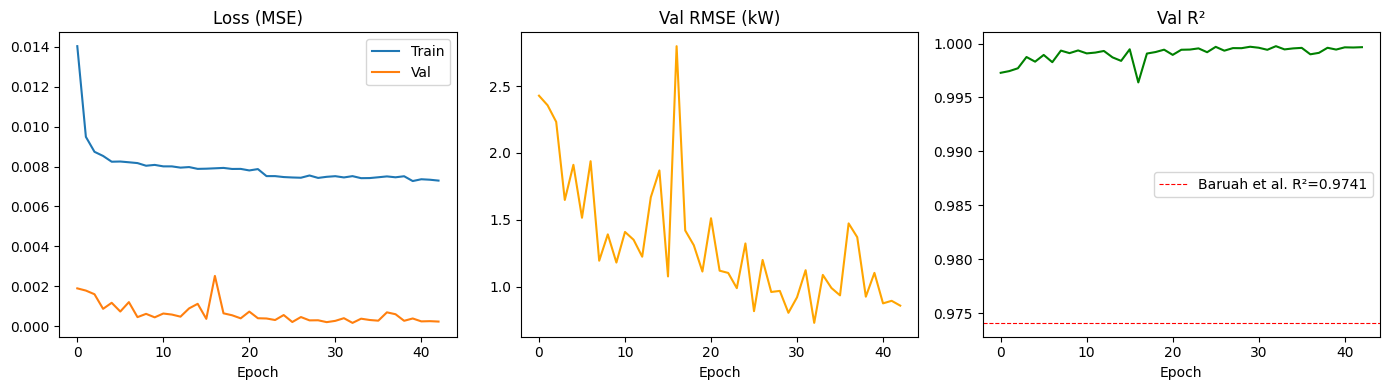

In [18]:
# ── Cell: Learning Curves ─────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'],   label='Val')
axes[0].set_title('Loss (MSE)')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history['val_rmse'], color='orange')
axes[1].set_title('Val RMSE (kW)')
axes[1].set_xlabel('Epoch')

axes[2].plot(history['val_r2'], color='green')
axes[2].axhline(0.9741, color='red', linestyle='--',
                linewidth=0.8, label='Baruah et al. R²=0.9741')
axes[2].set_title('Val R²')
axes[2].set_xlabel('Epoch')
axes[2].legend()

plt.tight_layout()
plt.show()